In [1]:
# key vocab
# ML kernel = a function that measures similarity between 2 inputs
# Gaussian Process = a model that predicts outputs by asking "what do similar training examples tell me?" using an ML kernel to define similarity

# Goal of this project
Use Gaussian Process Regression to predict IC50 values

Challenges of training a typical neural net
- High-dimensional (many features), low sample size (small data set) sequence data: it is hard for the neural net to learn thousands of parameters (since each sequence is represented by [num AA] x [20] features) from only about 1000 total sequences in the dataset
- Outliers in the data: most IC50 values cluster around 0.1, 1.0, 5.0, but some are UD, meaning non-neutralizable. These values are essentially infinite.

# Our Solution: Gaussian Process Regression (GPR)
- GPR does not try to fit the data to a specific function (like linear regression assumes the curve must be a line)
- GPR relies on the notion that points with similar inputs should have similar outputs
- The kernel defines "similarity"
- The prediction is a weighted average of nearby training points (aka similar sequences), where "nearby" is defined by the kernel
- **Possible future improvement:**: later combine this with escape mutation analysis because similarity may not just mean similar IC50 if one of the different amino acids provides an escape pathway

# Benefits of GPR
- **Works on small datasets**: it never tries to learn millions of parameters but rather memorizes training data and reasons by similarity
- **Measures uncertainty**: outputs a confidence interval alongside every prediction (i.e. indicates uncertainty if a sequence is very different from anything seen)

# The Kernel
- kernel choice is important because it defines the similarity function which is the basis for making the IC50 prediction for a new sequence

# Kernel Choices
- **option 1**: count number of positions that match bewteen 2 aligned sequences, divided by the length (percentage of residues that match -> percentage similarity)
- **option 2**: weight the percentage similarity of option 1 by how chemically similar substituted amino acids are
- **option 3**: ESM-based kernel which requires running sequences through ESM-2 (which provides amino acid embeddings based on biochemical properties) then measuring the cosine simlarity between them

# Mathematical Requirement for the Kernel Function
- must be symmetric and positive semi-definite
- intuition is simply that we want to measure how alike 2 inputs are in a way that is relevant to the output so that a new sequences predicted output depends on its similarity to sequences with known outputs

In [3]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 3.0 MB/s  0:00:03 eta 0:00:01

[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 31.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.4/20.4 MB 48.6 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:
import numpy as np
import pandas as pd
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import pearsonr

# Prepare Data

In [19]:
df = pd.read_csv('vrc01-catnap-data.csv')

# Drop rows with no sequence
df = df.dropna(subset=['Sequence'])

# Strip astericks from the ic50 end
df['IC50'] = df['IC50'].astype(str).str.replace('*', '', regex=False) # .astype(str) makes sure each entry is a string, then .str.replace() allows you to call the string method .replace() on the entire column at once

# Separate US rows from numeric rows
is_ud = df['IC50'].str.contains('UD', na=False) # long list of true/false for each row in dataframe
df_ud = df[is_ud].copy()
df_numeric = df[~is_ud].copy() # ~ means flip all booleans

# Convert IC50s to float and log-transform them
df_numeric['IC50'] = pd.to_numeric(df_numeric['IC50'], errors='coerce')
df_numeric = df_numeric.dropna(subset=['IC50'])
df_numeric['log_IC50'] = np.log10(df_numeric['IC50']) # apply the log

print(f"Numeric sequences: {len(df_numeric)}")
print(f"UD sequences: {len(df_ud)}")
print(f"log IC50 range: {df_numeric['log_IC50'].min():.2f} to {df_numeric['log_IC50'].max():.2f}")

Numeric sequences: 1663
UD sequences: 263
log IC50 range: -3.00 to 2.00


# Regression Task

In [21]:
# Store features and labels as lists
sequences = df_numeric['Sequence'].tolist()
y = df_numeric['log_IC50'].tolist()

# Sanity check
print(f"Number of sequences: {len(sequences)}")
print(f"Example sequence: {sequences[0][:50]}...")
print(f"Example log IC50: {y[0]:.3f}")

# Train/test split - 80% train, 20% test
X_train_seqs, X_test_seqs, y_train, y_test = train_test_split(
    sequences, y, test_size=0.2, random_state=42
)

print(f"\nTraining sequences: {len(X_train_seqs)}")
print(f"Test sequences: {len(X_test_seqs)}")

Number of sequences: 1663
Example sequence: MRVMGIRK-NC-QRLW--------RGGTL---FLGILM--IFSAAE----...
Example log IC50: -3.000

Training sequences: 1330
Test sequences: 333


# Define Kernel (similarity function)
- compute similarity between every pair of sequences
- 1330 training sequences -> 1330 * 1330 = 1.7 million pairs
- Each pair requires traversing ~1000 characters
- Slow in python; use vectorization in numpy to speed it up
- Instead of looping character by character through each sequence, convert each sequence to numpy array of characters and compute whole arrays at once

# Def of Vectorization
- using numpy to operate on whole arrays at once
- numpy's operations are implemented in C under the hood

In [29]:
def seqs_to_array(seqs):
    """Convert a list of strings to a 2D numpy array of characters (each row ia s sequence)"""
    return np.array([list(s) for s in seqs]) # list(s) turns string s into a list of its characters

def sequence_kernel(seqs_A, seqs_B):
    """
    Compute similarity matrix between two lists of sequences
    k(A, B) = fraction of non-both-gap positions where A and B match
    """
    arr_A = seqs_to_array(seqs_A) # shape (n, seq_len)
    arr_B = seqs_to_array(seqs_B) # shape (m, seq_len)

    n, m = len(seqs_A), len(seqs_B)
    K = np.zeros((n, m)) # initialize nxm array of zeros, one slot for each similarity score

    for i in range(n):
        # Compare sequence i in seqs_A to all seqs in seqs_B at once
        
        a_row = arr_A[i] # a_row: shape (seq_len, ), 1D vector
                         # arr_B: shape (m, seq_len), 2D numpy array

        a_is_gap = (a_row == '-')      # shape (seq_len, )
            # () not strictly necessary unless combine with &, |, ~ because == has lower operator precedence
            # () improves readability, though
        b_is_gap = (arr_B == '-')      # shape (m, seq_len)
        both_gap = a_is_gap & b_is_gap # shape (m, seq_len)
            # broadcasting: numpy broadcasts a_is_gap across all m rows automatically -> result is (m, seq_len)
        valid = ~both_gap              # shape (m, seq_len), positions we actually want

        # & means and for every element
        # | means or for every element
        # ~ means flip for every element (rather than !)
        # use & instead of and, | instead of or, and ~ instead of ! when working with numpy boolean arrays rather than individual boolean values

        char_match = (a_row == arr_B) # shape (m, seq_len)
        matches = char_match & valid # exclude gap+gap matches
        
        
        K[i, :] = matches.sum(axis=1) / valid.sum(axis=1)
            # at i-th index of K
            # sum matches and divide by number of valid positions (valid positions = not both gap) per sequence

            # matches.sum(axis=1) means for each of the m sequences in B, count how many positions matched
                # axis=1 means sum across y-dimension (sequence length dimension)
            # valid.sum(axis=1) means for each of the m sequences in B, count how many positions were valid (not both gaps)

            # axis=0 means sum down rows
            # axis=1 means sum across cols
        
    return K

# verify on small subset
K_tiny = sequence_kernel(X_train_seqs[:5], X_train_seqs[:5])
print("Tiny kernel matrix (should be all 1.0 on diagonal because seqsA and seqsB are same matrix here)")
print(np.round(K_tiny, 3))
        

Tiny kernel matrix (should be all 1.0 on diagonal because seqsA and seqsB are same matrix here)
[[1.    0.711 0.719 0.704 0.716]
 [0.711 1.    0.704 0.716 0.698]
 [0.719 0.704 1.    0.708 0.805]
 [0.704 0.716 0.708 1.    0.696]
 [0.716 0.698 0.805 0.696 1.   ]]


# Compute Full Kernel (Similarity) Matrix

In [32]:
import time

print("Computing training kernel matrix")
start = time.time()

K_train = sequence_kernel(X_train_seqs, X_train_seqs)

elapsed = time.time() - start

print(f"Done. Took {elapsed:.1f} seconds")
print(f"K_train shape: {K_train.shape}")
print(f"Diagonal min: {np.diag(K_train).min():.4f}") # should be 1.0
print(f"Diagonal max: {np.diag(K_train).max():.4f}") # should be 1.0
print(f"Off-diagonal range: {K_train[~np.eye(K_train.shape[0], dtype=bool)].min():.3f} to {K_train[~np.eye(K_train.shape[0], dtype=bool)].max():.3f}")
    # ~np.eye() is mask that's False on diagonals and True everywhere else (only look at non-diagonal entries)
    # np.eye() is true on diagonals and false everywhere else

Computing training kernel matrix
Done. Took 7.9 seconds
K_train shape: (1330, 1330)
Diagonal min: 1.0000
Diagonal max: 1.0000
Off-diagonal range: 0.519 to 1.000


Off-diagonal range upper-bound of 1.000 means some sequences are duplicated in dataset.

# Compute test kernel matrix
- find similarity of each test sequence to each training sequence
- when we ask GP to predict IC50 for test sequence, it will look at similarities of the test sequence to the training data and essentially ask which IC50s of the training sequences should be most similar to this one

In [33]:
print("Computing test kernel matrix")
start = time.time()
K_test = sequence_kernel(X_test_seqs, X_train_seqs)

elapsed = time.time() - start
print(f"Done. Took {elapsed:.1f} seconds")
print(f"K_test_shape: {K_test.shape}") # should be (333, 1330)

Computing test kernel matrix
Done. Took 2.3 seconds
K_test_shape: (333, 1330)


# Workflow
**Training**: GP looks at K_train (training vs training similarities) and y_train (to see how much similarities between sequences correlate with differences between IC50s)

**Prediction**: GP looks at K_test (test vs training similarities) to predict test IC50s.

GP learns a few parameters
- overall scale: are IC50 differences large or small across the dataset?
- noise level: how much random measurement error is there in IC50 values?

Maximum log likelihood trains these few parameters
- it finds the values that make the data most probable given the model

For every training example, GP computes similarity and, based on similarity using the kernel (similarity function), predicts IC50 and outputs confidence.

# GP Training vs Neural Net Training
**Neural Net Training**: iteratively adjust parameters over many epoch, features backpropagation and gradient descent

**GP fitting**: computes similarity at once, no epochs
- calling model.fit() on a GP inverts the kernel matrix and finds the best noise/scale parameters

# Train the GP

In [39]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, DotProduct

# Define the GP with a precomputed kernel
gp = GaussianProcessRegressor(
    kernel=DotProduct(sigma_0=0), # DotProduct kernel tells sklearn to treat input as precomputed kernel matrix
    normalize_y=True,
    n_restarts_optimizer=0, # don't try to tune kernel parameters
    optimizer=None # turn off optimizer
)

# Fit using precomputed kernel matrix (K_train), pass directly
gp.fit(K_train, y_train)

print("Fitting done.")
print(f"Learned noise level: {gp.alpha:.4f}")

Fitting done.
Learned noise level: 0.0000


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:310: RuntimeWarning: divide by zero encountered in log
  return np.log(np.hstack(theta))


In [43]:
%pip install scipy


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Pearson correlation: 0.4283
P-value: 2.7322e-16
Mean confidence interval width: 0.0000


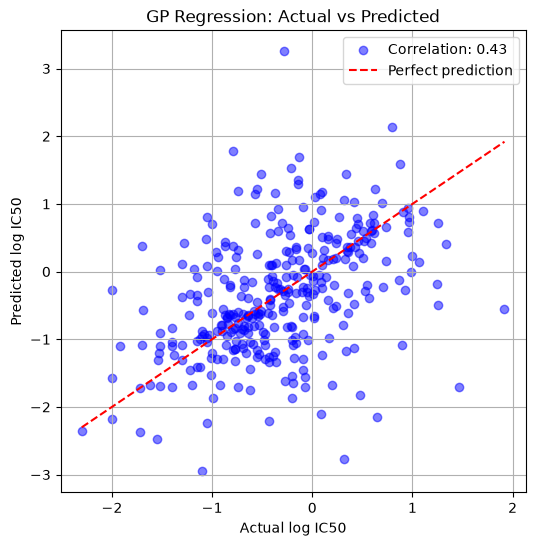

In [47]:
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

# Make predictions on test set
# return_std=True gives us confidence intervals
y_pred, y_std = gp.predict(K_test, return_std=True)

# Evaluate
correlation, pvalue = pearsonr(y_test, y_pred)
print(f"Pearson correlation: {correlation:.4f}")
print(f"P-value: {pvalue:.4e}")
print(f"Mean confidence interval width: {y_std.mean():.4f}")

# Scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue', label=f"Correlation: {correlation:.2f}")
plt.plot([min(y_test), max(y_test)],
         [min(y_test), max(y_test)],
          color='red', linestyle='--', label='Perfect prediction'
)
plt.xlabel('Actual log IC50')
plt.ylabel('Predicted log IC50')
plt.title('GP Regression: Actual vs Predicted')
plt.legend()
plt.grid(True)
plt.show()

Pearson correlation: 0.5584
P-value: 1.0779e-28
Mean uncertainty (std): 0.2251


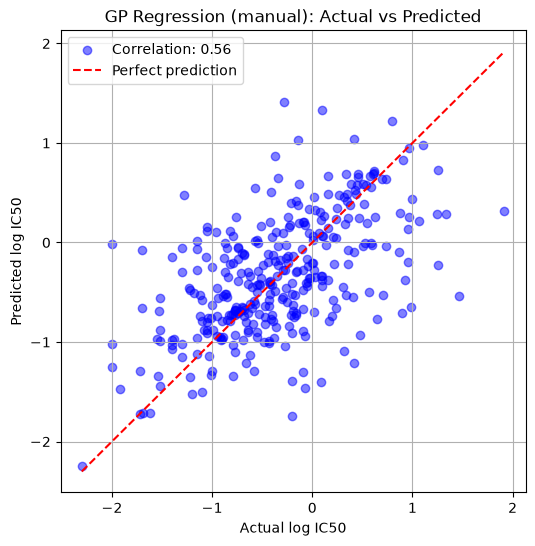

In [48]:
import numpy as np
from scipy.stats import pearsonr

# Add small noise to diagonal for numerical stability
# (prevents issues when inverting K_train)
noise = 0.01
K_train_stable = K_train + noise * np.eye(len(K_train))

# GP prediction formula: K_test @ inv(K_train) @ y_train
K_train_inv = np.linalg.inv(K_train_stable)
y_train_arr = np.array(y_train)
y_test_arr = np.array(y_test)

# Predict
alpha = K_train_inv @ y_train_arr        # shape (1330,)
y_pred_manual = K_test @ alpha           # shape (333,)

# Uncertainty — diagonal of (K_test_test - K_test @ K_train_inv @ K_test.T)
# K_test_test is similarity of each test seq to itself = 1.0 (diagonal)
variance = 1.0 - np.sum(K_test @ K_train_inv * K_test, axis=1)
std = np.sqrt(np.maximum(variance, 0))  # clip negatives from numerical error

# Evaluate
correlation, pvalue = pearsonr(y_test_arr, y_pred_manual)
print(f"Pearson correlation: {correlation:.4f}")
print(f"P-value: {pvalue:.4e}")
print(f"Mean uncertainty (std): {std.mean():.4f}")

# Plot
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 6))
plt.scatter(y_test_arr, y_pred_manual, alpha=0.5, color='blue', 
            label=f'Correlation: {correlation:.2f}')
plt.plot([min(y_test_arr), max(y_test_arr)], 
         [min(y_test_arr), max(y_test_arr)],
         color='red', linestyle='--', label='Perfect prediction')
plt.xlabel('Actual log IC50')
plt.ylabel('Predicted log IC50')
plt.title('GP Regression (manual): Actual vs Predicted')
plt.legend()
plt.grid(True)
plt.show()

In [49]:
# Build a dataframe of results including uncertainty
results = pd.DataFrame({
    'actual': y_test_arr,
    'predicted': y_pred_manual,
    'uncertainty': std,
    'error': np.abs(y_pred_manual - y_test_arr)
})

# Most confident predictions (lowest uncertainty)
print("Most confident predictions:")
print(results.nsmallest(5, 'uncertainty')[['actual', 'predicted', 'uncertainty', 'error']])

print()

# Least confident predictions (highest uncertainty)
print("Least confident predictions:")
print(results.nlargest(5, 'uncertainty')[['actual', 'predicted', 'uncertainty', 'error']])

print()

# Is the GP actually more accurate when it's more confident?
# Split into high/low confidence and compare errors
median_uncertainty = results['uncertainty'].median()
high_confidence = results[results['uncertainty'] <= median_uncertainty]
low_confidence = results[results['uncertainty'] > median_uncertainty]

print(f"Median uncertainty: {median_uncertainty:.4f}")
print(f"Mean error when confident: {high_confidence['error'].mean():.4f}")
print(f"Mean error when uncertain: {low_confidence['error'].mean():.4f}")

Most confident predictions:
       actual  predicted  uncertainty     error
250 -1.718785  -1.289972     0.036424  0.428812
46  -0.177309  -0.747261     0.044289  0.569952
142 -1.012285  -0.762729     0.045043  0.249555
240 -0.949814  -0.742186     0.045104  0.207628
262  0.614897   0.717560     0.046706  0.102663

Least confident predictions:
       actual  predicted  uncertainty     error
276 -0.435263  -1.012624     0.419720  0.577361
61  -0.229148   0.155962     0.415784  0.385110
130 -0.161151  -0.707205     0.404381  0.546054
227  0.926342  -0.374121     0.397669  1.300463
124  1.249443   0.290769     0.394955  0.958674

Median uncertainty: 0.2385
Mean error when confident: 0.3200
Mean error when uncertain: 0.5895


# Classifier then Regression

In [50]:
# Combine numeric and UD sequences
all_sequences = df_numeric['Sequence'].tolist() + df_ud['Sequence'].tolist()
all_labels = [0] * len(df_numeric) + [1] * len(df_ud)  # 0=non-UD, 1=UD

print(f"Total sequences: {len(all_sequences)}")
print(f"Non-UD (0): {all_labels.count(0)}")
print(f"UD (1): {all_labels.count(1)}")
print(f"Class balance: {all_labels.count(1)/len(all_labels)*100:.1f}% UD")

# Train/test split
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    all_sequences, all_labels, 
    test_size=0.2, 
    random_state=42,
    stratify=all_labels  # this ensures UD/non-UD ratio is same in train and test
)

print(f"\nTraining: {len(X_train_cls)} sequences")
print(f"Test: {len(X_test_cls)} sequences")
print(f"UD in training: {sum(y_train_cls)}")
print(f"UD in test: {sum(y_test_cls)}")

Total sequences: 1926
Non-UD (0): 1663
UD (1): 263
Class balance: 13.7% UD

Training: 1540 sequences
Test: 386 sequences
UD in training: 210
UD in test: 53


In [51]:
print("Computing classification training kernel matrix...")
start = time.time()
K_train_cls = sequence_kernel(X_train_cls, X_train_cls)
print(f"Done! Took {time.time()-start:.1f} seconds")

print("Computing classification test kernel matrix...")
start = time.time()
K_test_cls = sequence_kernel(X_test_cls, X_train_cls)
print(f"Done! Took {time.time()-start:.1f} seconds")

print(f"\nK_train_cls shape: {K_train_cls.shape}")
print(f"K_test_cls shape: {K_test_cls.shape}")
print(f"Diagonal check (should be 1.0): {np.diag(K_train_cls).min():.4f} to {np.diag(K_train_cls).max():.4f}")

Computing classification training kernel matrix...
Done! Took 10.8 seconds
Computing classification test kernel matrix...
Done! Took 2.7 seconds

K_train_cls shape: (1540, 1540)
K_test_cls shape: (386, 1540)
Diagonal check (should be 1.0): 1.0000 to 1.0000


# Train Classifier

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, classification_report, 
                             confusion_matrix, RocCurveDisplay)

# Train logistic regression on kernel matrix
# C controls regularization — higher C = trust training data more
clf = LogisticRegression(C=1.0, max_iter=1000)
clf.fit(K_train_cls, y_train_cls)

# Predict probabilities and class labels
y_prob = clf.predict_proba(K_test_cls)[:, 1]  # probability of being UD
y_pred_cls = clf.predict(K_test_cls)

# Evaluate
auc = roc_auc_score(y_test_cls, y_prob)
print(f"AUC-ROC: {auc:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test_cls, y_pred_cls, 
                            target_names=['Non-UD', 'UD']))
print()
print("Confusion Matrix:")
cm = confusion_matrix(y_test_cls, y_pred_cls)
print(f"                Predicted Non-UD  Predicted UD")
print(f"Actual Non-UD       {cm[0,0]}              {cm[0,1]}")
print(f"Actual UD           {cm[1,0]}              {cm[1,1]}")

AUC-ROC: 0.7711

Classification Report:
              precision    recall  f1-score   support

      Non-UD       0.87      1.00      0.93       333
          UD       1.00      0.04      0.07        53

    accuracy                           0.87       386
   macro avg       0.93      0.52      0.50       386
weighted avg       0.89      0.87      0.81       386


Confusion Matrix:
                Predicted Non-UD  Predicted UD
Actual Non-UD       333              0
Actual UD           51              2


In [ ]:
# ^class imbalance because so many more non-UD than UD

In [53]:
# class_weight='balanced' automatically adjusts for imbalance
# it makes UD mistakes ~7x more costly since UD is ~7x rarer
clf_balanced = LogisticRegression(C=1.0, max_iter=1000, class_weight='balanced')
clf_balanced.fit(K_train_cls, y_train_cls)

y_prob_bal = clf_balanced.predict_proba(K_test_cls)[:, 1]
y_pred_bal = clf_balanced.predict(K_test_cls)

auc_bal = roc_auc_score(y_test_cls, y_prob_bal)
print(f"AUC-ROC: {auc_bal:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test_cls, y_pred_bal,
                            target_names=['Non-UD', 'UD']))
print()
print("Confusion Matrix:")
cm = confusion_matrix(y_test_cls, y_pred_bal)
print(f"                Predicted Non-UD  Predicted UD")
print(f"Actual Non-UD       {cm[0,0]}              {cm[0,1]}")
print(f"Actual UD           {cm[1,0]}              {cm[1,1]}")

AUC-ROC: 0.7896

Classification Report:
              precision    recall  f1-score   support

      Non-UD       0.93      0.74      0.82       333
          UD       0.28      0.64      0.39        53

    accuracy                           0.72       386
   macro avg       0.60      0.69      0.60       386
weighted avg       0.84      0.72      0.76       386


Confusion Matrix:
                Predicted Non-UD  Predicted UD
Actual Non-UD       245              88
Actual UD           19              34


In [54]:
# Tune thresholds
# Try different thresholds and see how recall/precision tradeoff changes
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

print(f"{'Threshold':<12} {'UD Recall':<12} {'UD Precision':<15} {'False Positives':<15}")
print("-" * 55)

for thresh in thresholds:
    y_pred_thresh = (y_prob_bal >= thresh).astype(int)
    cm = confusion_matrix(y_test_cls, y_pred_thresh)
    ud_recall = cm[1,1] / (cm[1,0] + cm[1,1])        # caught UD / all actual UD
    ud_precision = cm[1,1] / (cm[0,1] + cm[1,1]) if (cm[0,1] + cm[1,1]) > 0 else 0
    false_positives = cm[0,1]
    print(f"{thresh:<12} {ud_recall:<12.2f} {ud_precision:<15.2f} {false_positives:<15}")

Threshold    UD Recall    UD Precision    False Positives
-------------------------------------------------------
0.1          1.00         0.14            315            
0.2          1.00         0.17            264            
0.3          0.91         0.19            206            
0.4          0.81         0.23            145            
0.5          0.64         0.28            88             


In [55]:
# Full Pipeline

THRESHOLD = 0.4

def predict_ic50(new_sequences):
    """
    Full pipeline:
    1. Classify as UD or non-UD
    2. For predicted non-UD, run GP regression
    3. Return predictions with confidence
    """
    results = []
    
    # Step 1 — compute kernel matrices for new sequences
    K_new_cls = sequence_kernel(new_sequences, X_train_cls)
    K_new_reg = sequence_kernel(new_sequences, X_train_seqs)
    
    # Step 2 — classify
    ud_probs = clf_balanced.predict_proba(K_new_cls)[:, 1]
    is_ud_pred = ud_probs >= THRESHOLD
    
    # Step 3 — regression for predicted non-UD sequences
    y_reg_pred = K_new_reg @ alpha   # alpha from manual GP
    variance = 1.0 - np.sum(K_new_reg @ K_train_inv * K_new_reg, axis=1)
    uncertainty = np.sqrt(np.maximum(variance, 0))
    
    # Step 4 — compile results
    for i, seq in enumerate(new_sequences):
        if is_ud_pred[i]:
            results.append({
                'sequence': seq[:30] + '...',
                'prediction': 'UD',
                'ud_probability': f"{ud_probs[i]:.2f}",
                'log_ic50': None,
                'uncertainty': None
            })
        else:
            results.append({
                'sequence': seq[:30] + '...',
                'prediction': 'Non-UD',
                'ud_probability': f"{ud_probs[i]:.2f}",
                'log_ic50': f"{y_reg_pred[i]:.3f}",
                'ic50': f"{10**y_reg_pred[i]:.4f} ug/mL",
                'uncertainty': f"{uncertainty[i]:.3f}"
            })
    
    return pd.DataFrame(results)

# Test on a few test sequences
print("Testing pipeline on 10 test sequences:")
sample_seqs = X_test_cls[:10]
output = predict_ic50(sample_seqs)
print(output.to_string())

Testing pipeline on 10 test sequences:
                            sequence prediction ud_probability log_ic50          ic50 uncertainty
0  MRVMGIRK-NY-RHLW--------RWGTM-...     Non-UD           0.29   -0.170  0.6768 ug/mL       0.244
1  MRVMGMQR-SW-QHLG--------KWGLL-...     Non-UD           0.37   -0.891  0.1284 ug/mL       0.073
2  MRVMGTQR-NY-SPLW--------RWGMI-...     Non-UD           0.36   -0.537  0.2905 ug/mL       0.093
3  MRVTGIRK-NY-RHLW--------RWGTM-...     Non-UD           0.25    0.138  1.3743 ug/mL       0.093
4  MRVMGILR-NY-QQWW--------IWGIL-...         UD           0.63      NaN           NaN         NaN
5  MRVRGISR-NW-PQWW--------IWGIL-...         UD           0.61      NaN           NaN         NaN
6  MRVKETQR-NW-PNLW--------KWGTL-...         UD           0.48      NaN           NaN         NaN
7  MKVKETMK-NC-QLLW--------KGGIL-...     Non-UD           0.40   -0.037  0.9185 ug/mL       0.097
8  MRVRGMLR-NC-PPWW--------IWASL-...         UD           0.54      NaN        